# Лаб. 2, варіант 4

$$y'' + x^2 y' + y = \sin x, \quad x \in [0, 1], \quad y(0) = 1,\ y(1) = 0$$

$$y'' + p(x)\,y' + q(x)\,y = f(x), \qquad p = x^2,\ q = 1,\ f = \sin x$$

Сітка: $h = 1/N, \quad x_i = i h, \quad y_0 = 1,\ y_N = 0$

Центральні різниці:

$$y'_i \approx \frac{y_{i+1} - y_{i-1}}{2h}, \qquad y''_i \approx \frac{y_{i-1} - 2y_i + y_{i+1}}{h^2}$$

$$\frac{y_{i-1} - 2y_i + y_{i+1}}{h^2} + p_i\,\frac{y_{i+1} - y_{i-1}}{2h} + q_i y_i = f_i \quad \Big| \cdot h^2$$

$$\Big(1 - \frac{h p_i}{2}\Big) y_{i-1} + \big(-2 + h^2 q_i\big) y_i + \Big(1 + \frac{h p_i}{2}\Big) y_{i+1} = h^2 f_i$$

$$a_i y_{i-1} + b_i y_i + c_i y_{i+1} = d_i$$

$$a_i = 1 - \frac{h p_i}{2}, \quad b_i = -2 + h^2 q_i, \quad c_i = 1 + \frac{h p_i}{2}, \quad d_i = h^2 f_i$$

Граничні умови: $d_1 = d_1 - a_1 y_0, \quad d_{N-1} = d_{N-1} - c_{N-1} y_N$

Прогонка: $y_i = \alpha_i y_{i+1} + \beta_i$

$$\alpha_1 = -\frac{c_1}{b_1}, \quad \beta_1 = \frac{d_1}{b_1}$$

$$\alpha_i = \frac{-c_i}{b_i + a_i \alpha_{i-1}}, \quad \beta_i = \frac{d_i - a_i \beta_{i-1}}{b_i + a_i \alpha_{i-1}}$$

$$y_{N-1} = \beta_{N-1}, \qquad y_i = \alpha_i y_{i+1} + \beta_i, \quad i = N-2, \dots, 1$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt

p = lambda x: x**2
q = lambda x: np.ones_like(x)
f = lambda x: np.sin(x)

a_, b_ = 0.0, 1.0
ya, yb = 1.0, 0.0


def thomas(a, b, c, d):
    n = len(d)
    alpha, beta = np.zeros(n), np.zeros(n)
    alpha[0], beta[0] = -c[0] / b[0], d[0] / b[0]
    for i in range(1, n):
        den = b[i] + a[i] * alpha[i - 1]
        alpha[i] = -c[i] / den
        beta[i] = (d[i] - a[i] * beta[i - 1]) / den
    y = np.zeros(n)
    y[-1] = beta[-1]
    for i in range(n - 2, -1, -1):
        y[i] = alpha[i] * y[i + 1] + beta[i]
    return y


def solve(N):
    h = (b_ - a_) / N
    x = np.linspace(a_, b_, N + 1)
    xi = x[1:-1]
    a = 1 - h * p(xi) / 2
    b = -2 + h**2 * q(xi)
    c = 1 + h * p(xi) / 2
    d = h**2 * f(xi)
    d[0] -= a[0] * ya
    d[-1] -= c[-1] * yb
    y = np.empty(N + 1)
    y[0], y[-1] = ya, yb
    y[1:-1] = thomas(a, b, c, d)
    return x, y

In [2]:
N = 10
x, y = solve(N)
print("   x        y")
for xv, yv in zip(x, y):
    print(f"{xv:5.2f}  {yv:9.6f}")

_, y2 = solve(2 * N)
print()
print("max|y_N - y_2N| =", np.max(np.abs(y - y2[::2])))

   x        y
 0.00   1.000000
 0.10   0.903581
 0.20   0.799226
 0.30   0.689293
 0.40   0.576425
 0.50   0.463494
 0.60   0.353508
 0.70   0.249486
 0.80   0.154292
 0.90   0.070457
 1.00   0.000000

max|y_N - y_2N| = 0.00010741074933340311


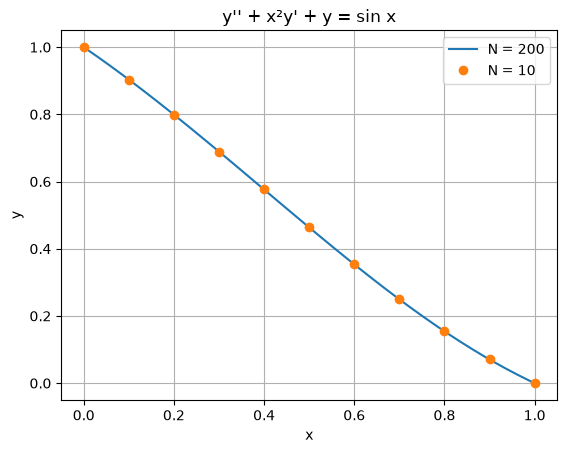

In [3]:
xf, yf = solve(200)
plt.plot(xf, yf, label="N = 200")
plt.plot(x, y, "o", label=f"N = {N}")
plt.xlabel("x"); plt.ylabel("y"); plt.grid(True); plt.legend()
plt.title("y'' + x²y' + y = sin x")
plt.show()